# Figure 1a
One fixation trajectory at $r=1$. Monitored vertices are drawn as regular polygons, and the row below each snapshot shows what the observer sees.

In [1]:
import json

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
POS = {
  0: (0.55, 1.55), 1: (2.45, 1.85), 2: (5.2, 1.3), 3: (0.0, 0.0), 4: (1.0, 0.0), 5: (2.0, 0.0), 6: (3.0, 0.0),
  7: (4.0, 0.0), 8: (0.0, -1.0), 9: (1.0, -1.0), 10: (2.0, -1.0), 11: (3.0, -1.0), 12: (4.9, -0.75),
}
MONITORED = {1: 3, 4: 4, 8: 5, 11: 6}
R = 0.2
two, one = [tuple(e) for e in d['two_way']], [tuple(e) for e in d['one_way']]


def regions(ax, labels):
  box = 'round,pad=0.12,rounding_size=0.35'
  ax.add_patch(FancyBboxPatch((0.2, 1.15), 5.35, 1.0, boxstyle=box, facecolor=S.LPURPLE, alpha=0.5, lw=0, zorder=0))
  ax.add_patch(FancyBboxPatch((-0.32, -1.32), 5.55, 1.64, boxstyle=box, facecolor=S.LGREEN, alpha=0.5, lw=0, zorder=0))
  if labels:
    ax.text(5.8, 1.65, 'source', fontsize=7, ha='left', va='center', color=S.INK)
    ax.text(5.48, -0.5, 'sink', fontsize=7, ha='left', va='center', color=S.INK)


def draw(ax, fills, origin=None, labels=False):
  regions(ax, labels)
  S.draw_graph(ax, POS, two, fills, R=R, one_way=one, shapes=MONITORED, gap=0.04, link_lw=0.8)
  if origin is not None:
    x, y = POS[origin]
    S.arrow(ax, (x - 0.62, y + 0.38), (x - 0.2 * 0.85 - 0.04, y + 0.1), color=S.ORIGIN, lw=1.0, scale=7)

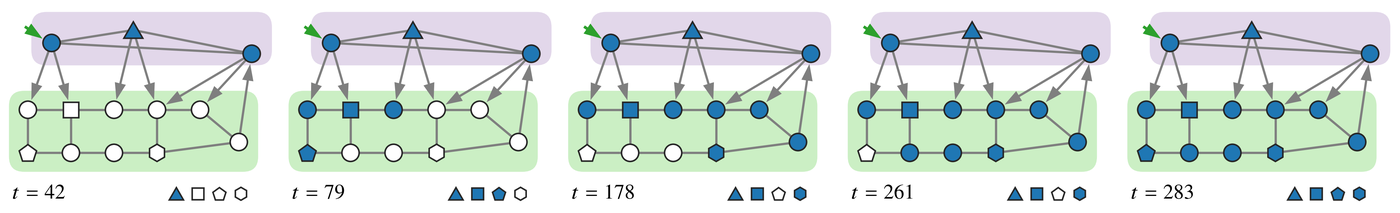

In [3]:
snaps = [(t, set(mut)) for t, mut in d['snapshots']] + [(d['t_fix'], set(range(d['N'])))]
fig = plt.figure(figsize=(7.0, 3.1))
for k, (t, mut) in enumerate(snaps):
  ax = fig.add_axes([0.003 + 0.199 * k, 0.635, 0.193, 0.345])
  draw(ax, {v: S.MUTANT if v in mut else S.WILD for v in range(d['N'])}, origin=d['origin'])
  for j, (v, n) in enumerate(MONITORED.items()):
    S.polygon(ax, (3.45 + 0.5 * j, -1.95), n, 0.15, S.MUTANT if v in mut else S.WILD, zorder=4)
  ax.text(-0.35, -1.95, r'$t=%d$' % t, ha='left', va='center', fontsize=7.5)
  ax.set_xlim(-0.55, 5.75)
  ax.set_ylim(-2.25, 2.4)
S.save_panel(fig, 'a')